# 01 · Data cleaning and exploratory analysis

**Dataset:** Fuhrländer FL2500 wind farm, 5 turbines × 2.5 MW, 2012–2014, 5-min SCADA + controller alarm log
([source](https://github.com/alecuba16/fuhrlander), Eclipse Public License v2.0, author Alejandro Blanco-M.).

Run `python scripts/download_data.py && python scripts/prepare_fuhrlander.py` first.
This notebook reads the cleaned standard tables in `data/processed/fuhrlander/`.

In [1]:
import pandas as pd, numpy as np
from IPython.display import Image, display
from predmaint import pipeline, report
from predmaint.config import load_config
from predmaint.data import load_events
from predmaint.features import operating_mask
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)

cfg = load_config("configs/fuhrlander.yaml")  # paths resolve from the repo root
df = pipeline.prepare(cfg)          # standard columns + model features
events = load_events(cfg)
print(f"{len(df):,} rows (10-min), {df.asset.nunique()} turbines, {df.timestamp.min():%Y-%m-%d} → {df.timestamp.max():%Y-%m-%d}")

534,422 rows (10-min), 5 turbines, 2012-01-01 → 2014-12-08


## 1. Coverage and data-quality issues found

In [2]:
cov = df.groupby(["asset", df.timestamp.dt.to_period("Q")]).size().unstack(0)
expected = cov.index.map(lambda q: (q.end_time - q.start_time).days * 144 + 144)
(cov.div(expected, axis=0) * 100).round(0).astype("Int64")

asset,80,81,82,83,84
timestamp,,,,,
2012Q1,99,99,97,91,99
2012Q2,99,99,99,97,99
2012Q3,98,98,98,98,98
2012Q4,99,99,99,99,99
2013Q1,61,61,51,61,61
2013Q2,23,23,23,23,23
2013Q4,6,3,6,6,3
2014Q1,70,70,70,70,70
2014Q2,91,95,95,95,77


Findings (handled in `scripts/prepare_fuhrlander.py`):
* **No SCADA data June–November 2013** for any turbine (the alarm log continues). Events in that gap can't be scored.
* ~3,400 alarm rows had the start **year typed as 2017** instead of 2014 (end time and neighbouring rows are 2014) → corrected.
* Temperature sensors write **exact 0.0** when the logger drops out → treated as missing.
* 5-min data resampled to the industry-standard **10-min** averages.

In [3]:
temps = [c for c in df.columns if c.endswith("_temp")]
df[temps].isna().mean().mul(100).round(1).sort_values(ascending=False).head(8).rename("% missing")

converter_coolwater_return_temp    0.8
converter_heatsink_temp            0.8
ambient_temp                       0.6
gearbox_oil_temp                   0.0
gearbox_temp                       0.0
gearbox_bearing_151_temp           0.0
gearbox_bearing_152_temp           0.0
gearbox_bearing_452_temp           0.0
Name: % missing, dtype: float64

## 2. Normal operation filter
Only rows where the turbine produces (> 2 % of rated power) at > 3 m/s wind are used to learn normal behaviour.

normal operation: 64% of rows


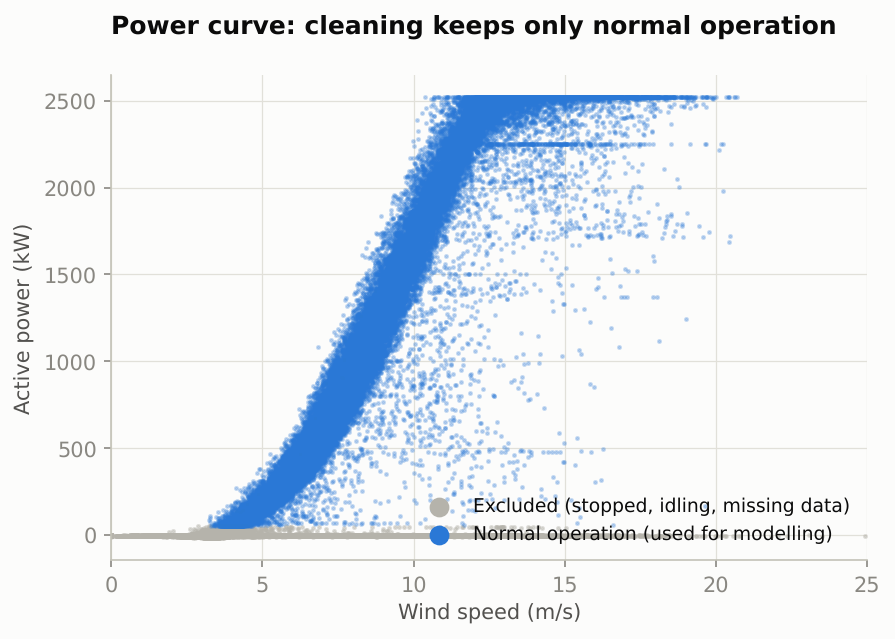

In [4]:
op = operating_mask(df, cfg)
print(f"normal operation: {op.mean():.0%} of rows")
display(Image("../reports/figures/02_power_curve.png", width=600))

## 3. Fault events
Two kinds of labels are derived from the alarm log and the power data:

In [5]:
summary = events.assign(year=events.start.dt.year).groupby(["kind", "component", "year"]).size().unstack(fill_value=0)
summary

year                        2012  2013  2014
kind          component                     
major_outage  turbine          3     2     4
thermal_alarm gearbox         15     7     6
              generator       13     0     1
              main_bearing     0     1     6
              transformer      7     9     2

In [6]:
events[events.kind == "major_outage"][["asset", "start", "end", "description"]]

,asset,start,end,description
9,80,2013-01-15,2013-01-21,"6 days down; stop alarms: M.bear. Error Pressure, MGB PressOil In < SL"
16,81,2012-11-23,2012-12-09,"16 days down; stop alarms: M.bear. Error Pressure, 4-20mA signal stop, Safety sys acti..."
17,81,2013-03-11,2013-03-17,6 days down; stop alarms: Nacel.pos<>wind vane
23,81,2014-11-15,2014-11-21,"6 days down; stop alarms: MBSOilPpStartingRate, Yaw thermal relay, Yaw Inv Error Repea..."
26,82,2012-03-18,2012-03-30,"12 days down; stop alarms: Gen <> RotIGR > SH, Rep. error by yawing, Repeating error, ..."
46,83,2012-06-17,2012-06-22,"5 days down; stop alarms: Safety sys activated, Yaw thermal relay, Nacel.pos<>wind van..."
57,83,2014-07-11,2014-08-05,"25 days down; stop alarms: Gen <> RotIGR > SH, PLU PCH Temp>SHH, Rep. error by yawing,..."
72,84,2014-01-21,2014-01-28,"7 days down; stop alarms: PLU PCH Error, PLU PCH Warning, MBSOilPpStartingRate, Safety..."
73,84,2014-06-07,2014-09-22,"107 days down; stop alarms: Safety sys activated, MBS FuseTrip HydOilPp, PLU PCO warni..."


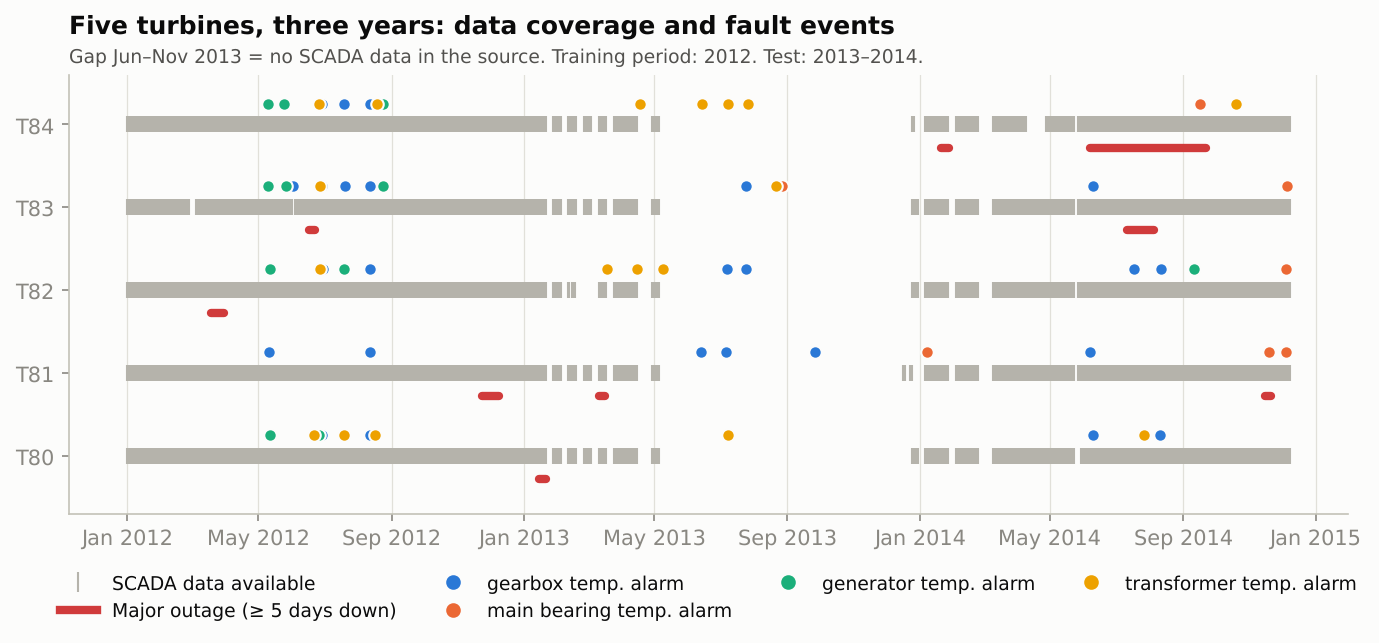

In [7]:
display(Image("../reports/figures/01_data_overview.png", width=900))

Observations:
* Gearbox temperature alarms cluster in **summer** for every turbine, so part of them is simply hot weather plus high load.
* **T81** has by far the most gearbox alarms, every summer: a candidate developing fault.
* **T84** was down for **107 days** from June 2014 (converter, pitch and hydraulic errors), the largest failure in the data.

## 4. Is T81 really different? Temperature vs load

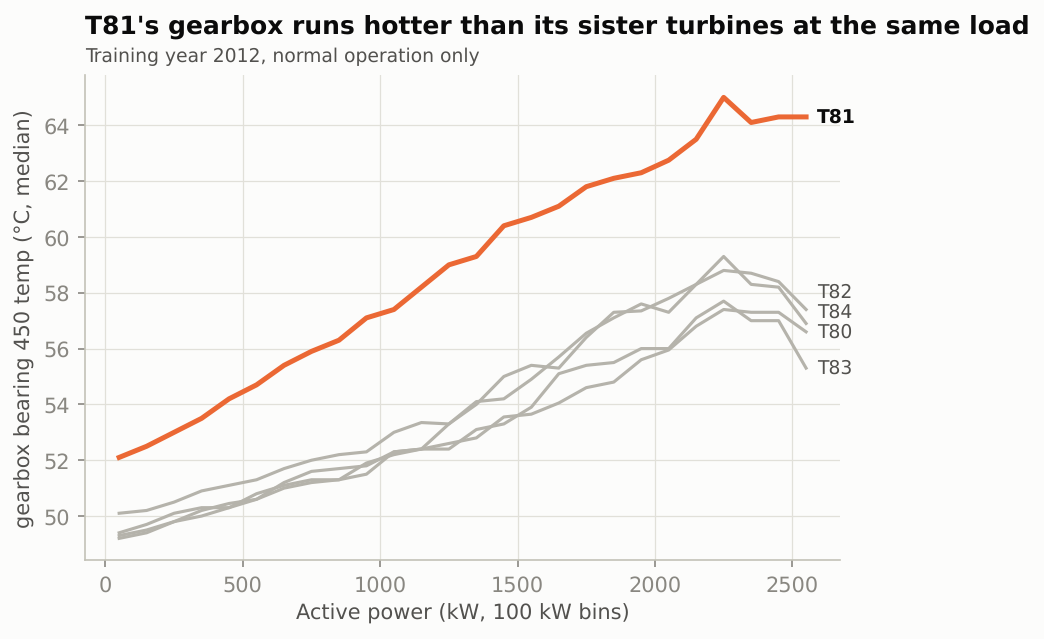

,gearbox_bearing_450_temp,gearbox_oil_temp,gearbox_temp,ambient_temp
asset,,,,
80,56.8,57.9,73.7,18.7
81,64.3,63.0,78.1,19.5
82,58.3,58.6,74.8,19.6
83,56.3,56.9,76.6,18.9
84,57.6,58.4,77.2,19.1


In [8]:
display(Image("../reports/figures/03_gearbox_temp_vs_load.png", width=650))
m = op & (df.timestamp < "2013-01-01") & (df.power > 2000)
df[m].groupby("asset")[["gearbox_bearing_450_temp", "gearbox_oil_temp", "gearbox_temp", "ambient_temp"]].median().round(1)

At the same load and similar ambient temperature, T81's gearbox bearings and oil run **4–6 °C hotter**
than the four sister turbines, already in 2012. A model trained on T81's own history would learn this as "normal".
That's why the main model compares each turbine with its sister turbines (**fleet mode**, see notebook 02 / `src/predmaint/nbm.py`).

## 5. Ambient temperature drives the summer alarms

In [9]:
d = df[op].assign(month=df.timestamp.dt.month)
pd.DataFrame({
    "ambient °C": d.groupby("month").ambient_temp.median(),
    "gearbox °C": d.groupby("month").gearbox_temp.median(),
    "gearbox alarms": events[events.component == "gearbox"].start.dt.month.value_counts(),
}).fillna(0).round(1)

,ambient °C,gearbox °C,gearbox alarms
1,7.0,65.7,0.0
2,5.9,65.9,0.0
3,10.1,66.0,0.0
4,12.2,67.3,0.0
5,15.4,69.3,1.0
6,21.0,70.7,9.0
7,21.3,70.3,10.0
8,22.9,72.4,7.0
9,20.3,68.0,1.0
10,17.4,64.9,0.0


Gearbox alarms happen only in June–September, when ambient and gearbox temperatures peak. A useful early-warning
model must therefore **explain away weather and load** and flag only the *unexplained* heat. That's the job of the
normal-behaviour model in the next step.